# Form case: how it works ($r$, $\rho$, MI)

Companion to [`form_figure.ipynb`](form_figure.ipynb), which builds the paper figure. This notebook shows what the figure leaves out: the construction, every pair type in every condition, the population values the sample statistics should follow, the per-SPI means a strength summary would report, and the sensitivity checks quoted in the [README](../README.md).

Design (`form_ladder_261028.py`, generator `mtsspi.generators.generate_form_ladder_mts`): $M=12$ channels in three blocks of four observe one standardised AR(1) latent $u$ ($a=0.8$), $T=2000$. Channel $i$ is $w_i=(u+s_i\varepsilon_i)/\sqrt{1+s_i^2}$ observed through its block's map $g$, with $s_i$ log-spaced on $[0.2,1]$ and the same four values in every block. Block 1 is linear; block 2 is linear or monotone, $\sinh 2w$; block 3 is linear or folded, $w^2$. Replicate $k$ uses the same draws in every condition. SPIs are computed locally with pyspi: $r$ (`cov_EmpiricalCovariance` on standardised channels), Spearman $\rho$ and KSG MI ($k=4$).

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for p in (ROOT, ROOT / 'src'):
    if str(p) not in sys.path[:2]: sys.path.insert(0, str(p))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from research.cases.case_run import ordered, z
from research.cases.r_rho_mi import form_ladder_261028 as F

REPS = 20
rows, mats = [], {}
for level, kw in F.LEVELS.items():
    for rep in range(REPS):
        x, it = F.make(kw, rep)
        m = F.stats(x)
        mats[level, rep] = (x, it, m)
        rows.append({'level': level, 'rep': rep,
                     **{f'mean_{k}': ordered(v).mean() for k, v in m.items()},
                     'z_r_rho': z(m['r'], m['rho']), 'z_rho_mi': z(m['rho'], m['mi']), 'z_r_mi': z(m['r'], m['mi']),
                     **F.linfoot_z(m)})
frame = pd.DataFrame(rows)
stored = pd.read_csv(ROOT / 'results/cases/form-ladder-261028/z_by_recording.csv')
check = frame.merge(stored, on=['level', 'rep'], suffixes=('', '_stored'))
print('max |z - stored z|:', max(np.abs(check[c] - check[c + '_stored']).max() for c in ['z_r_rho', 'z_rho_mi', 'z_r_mi', 'x_rho_milin']))

max |z - stored z|: 1.1102230246251565e-16


## One recording per condition

Channels (first 300 samples) and the three $12\times12$ matrices for replicate 0. Rows and columns are ordered linear block, block 2, block 3.

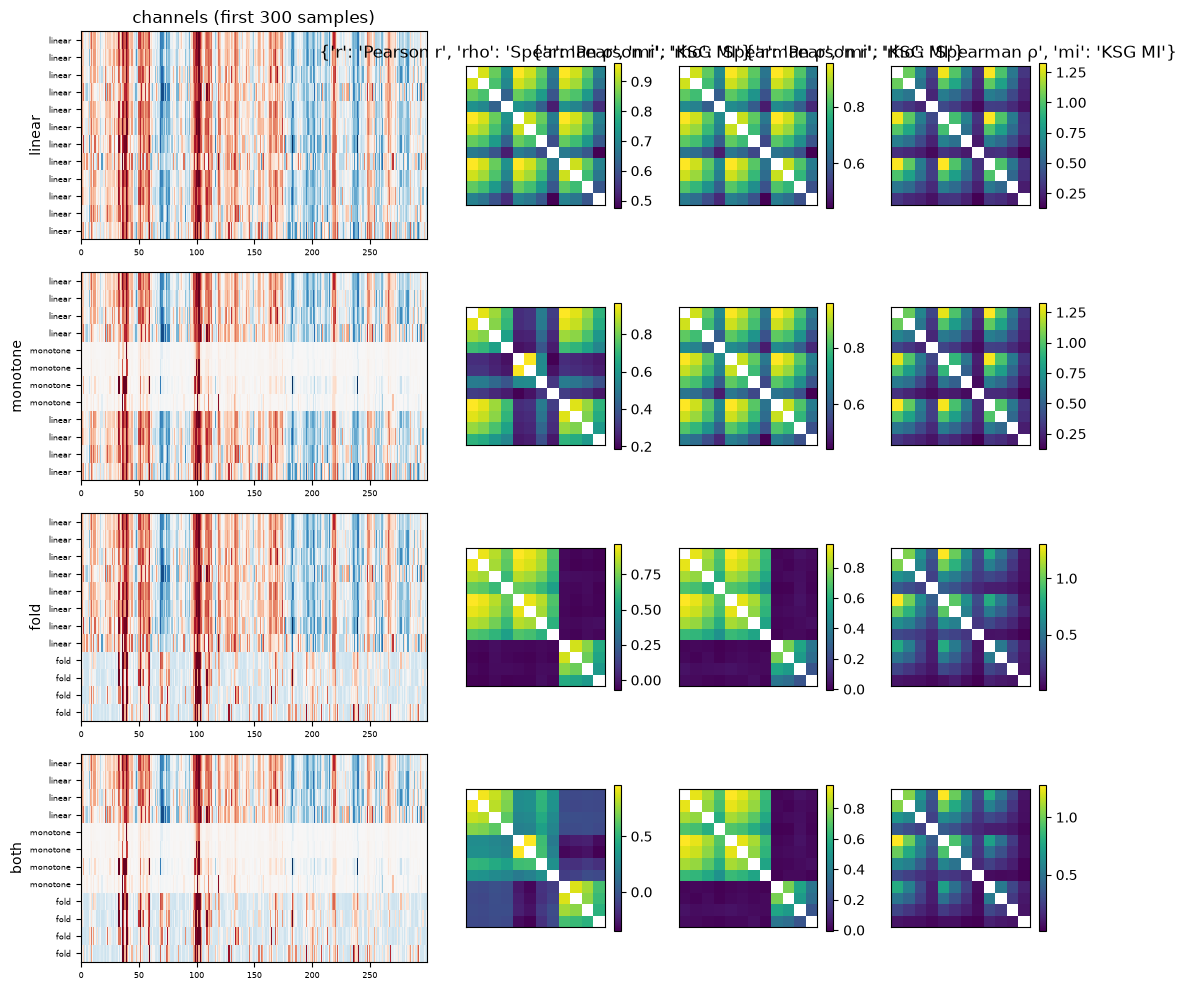

In [2]:
fig, axes = plt.subplots(4, 4, figsize=(11, 10), gridspec_kw=dict(width_ratios=[2, 1, 1, 1]))
for row, level in zip(axes, F.LEVELS):
    x, it, m = mats[level, 0]
    row[0].imshow(x[:300].T, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='none')
    row[0].set(ylabel=level, yticks=range(12), yticklabels=it.types)
    row[0].tick_params(labelsize=6)
    for ax, key in zip(row[1:], ['r', 'rho', 'mi']):
        a = np.array(m[key], float); np.fill_diagonal(a, np.nan)
        im = ax.imshow(a, cmap='viridis', interpolation='none'); ax.set(xticks=[], yticks=[])
        fig.colorbar(im, ax=ax, shrink=0.7)
        if level == 'linear': ax.set_title({'r': 'Pearson r', 'rho': 'Spearman ρ', 'mi': 'KSG MI'})
axes[0, 0].set_title('channels (first 300 samples)')
fig.tight_layout()

## Edge planes by pair type

Every ordered pair of replicate 0, coloured by pair type: linear (grey), monotone if either channel is monotone (blue), fold if either channel is folded (pink). The left column is the $r$–$\rho$ rung, the right the $\rho$–MI rung; $z$ is in the corner.

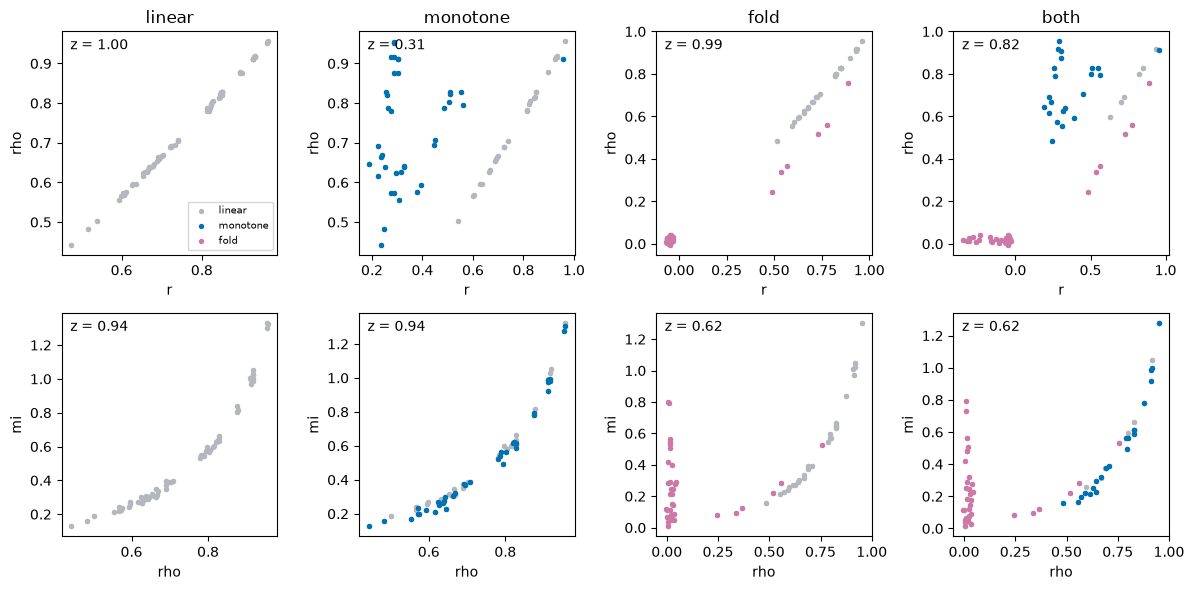

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, level in enumerate(F.LEVELS):
    x, it, m = mats[level, 0]
    rel = ordered(F.relation(it.types))
    for ax, (a, b) in zip(axes[:, j], [('r', 'rho'), ('rho', 'mi')]):
        for kind, colour in F.PAIR_INK.items():
            sel = rel == kind
            ax.scatter(ordered(m[a])[sel], ordered(m[b])[sel], s=8, color=colour, label=kind)
        ax.text(0.04, 0.92, f'z = {z(m[a], m[b]):.2f}', transform=ax.transAxes)
        ax.set(xlabel=a, ylabel=b)
    axes[0, j].set_title(level)
axes[0, 0].legend(fontsize=7, loc='lower right')
fig.tight_layout()

## Population values

With $c_{ij}=\mathrm{corr}(w_i,w_j)=1/\sqrt{(1+s_i^2)(1+s_j^2)}$ and jointly Gaussian $w$, Pearson $r$ after the maps is: $c$ for linear pairs; $\kappa c$ with $\kappa=2e^{2}/\sqrt{(e^{8}-1)/2}\approx0.38$ for monotone–linear pairs (Stein's lemma); $\sinh(4c)/\sinh 4$ for monotone–monotone pairs; $0$ for any pair with exactly one folded channel; $c^2$ for fold–fold pairs. Spearman $\rho=(6/\pi)\arcsin(c/2)$ for every pair without a fold, because a strictly increasing map leaves ranks unchanged, and Gaussian MI is $-\tfrac12\log(1-c^2)$. The monotone block therefore reorders edges for $r$ only: weak monotone–linear pairs keep a fixed fraction of $c$, while the monotone–monotone curve compresses weak pairs much more than strong ones.

kappa = 0.3829


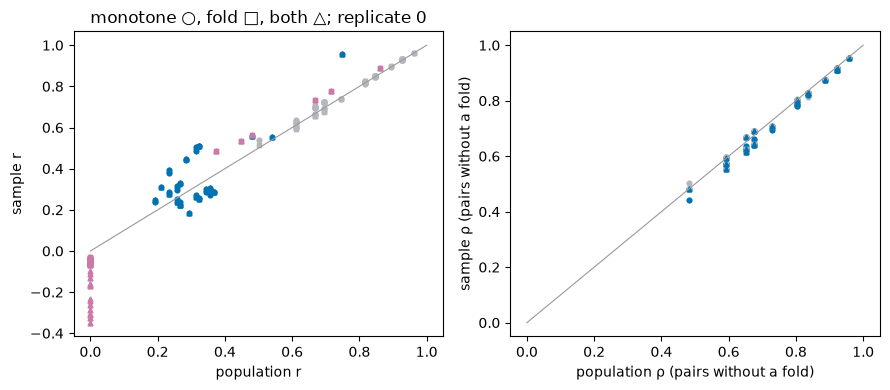

In [4]:
a = 2.0
kappa = a * np.exp(a**2 / 2) / np.sqrt((np.exp(2 * a**2) - 1) / 2)
def population(types, s):
    load = 1 / np.sqrt(1 + s**2)
    c = np.outer(load, load)
    t = np.asarray(types)
    r = c.copy()
    mono = (t == 'monotone'); fold = (t == 'fold')
    one_mono = mono[:, None] ^ mono[None, :]
    r[one_mono & ~(fold[:, None] | fold[None, :])] *= kappa
    both_mono = mono[:, None] & mono[None, :]
    r[both_mono] = np.sinh(a**2 * c[both_mono]) / np.sinh(a**2)
    r[fold[:, None] ^ fold[None, :]] = 0
    r[fold[:, None] & fold[None, :]] = c[fold[:, None] & fold[None, :]] ** 2
    rho = 6 / np.pi * np.arcsin(c / 2)
    rho[fold[:, None] | fold[None, :]] = np.nan
    return r, rho, c
print(f'kappa = {kappa:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for level, marker in [('monotone', 'o'), ('fold', 's'), ('both', '^')]:
    x, it, m = mats[level, 0]
    r_pop, rho_pop, _ = population(it.types, it.noise_stds)
    rel = ordered(F.relation(it.types))
    for kind, colour in F.PAIR_INK.items():
        sel = rel == kind
        axes[0].scatter(ordered(r_pop)[sel], ordered(m['r'])[sel], s=10, marker=marker, color=colour)
        axes[1].scatter(ordered(rho_pop)[sel], ordered(m['rho'])[sel], s=10, marker=marker, color=colour)
for ax, name in zip(axes, ['r', 'ρ (pairs without a fold)']):
    ax.plot([0, 1], [0, 1], color='0.6', lw=0.8); ax.set(xlabel=f'population {name}', ylabel=f'sample {name}')
axes[0].set_title('monotone ○, fold □, both △; replicate 0')
fig.tight_layout()

Pairs involving the heavy-tailed $\sinh$ channels scatter widely around their population values at $T=2000$. The monotone–fold pairs of the mixed recording are the extreme case: population $r=0$, but sample $r$ spans roughly $-0.35$ to $+0.3$ across replicates 0–4 (replicate 0, shown, is the most negative). This sampling instability is why $z(r,\rho)$ has a larger s.d. in the monotone and mixed conditions.

## What a per-SPI strength summary sees

Mean over the 132 ordered entries of each SPI, then mean (s.d.) over the 20 replicates. This is the comparison the draft text asks for: under the monotone map, the means of $\rho$ and MI should stay at their linear values and only the mean of $r$ should fall, which a strength summary cannot distinguish from weaker coupling.

In [5]:
cols = ['mean_r', 'mean_rho', 'mean_mi']
g = frame.groupby('level', sort=False)[cols]
print(g.mean().round(3).astype(str) + ' (' + g.std().round(3).astype(str) + ')')

                 mean_r      mean_rho        mean_mi
level                                               
linear    0.764 (0.003)  0.75 (0.005)  0.541 (0.004)
monotone  0.572 (0.031)  0.75 (0.005)  0.529 (0.004)
fold      0.378 (0.019)  0.36 (0.005)   0.36 (0.005)
both      0.276 (0.036)  0.36 (0.005)  0.346 (0.005)


## SPI–SPI coordinates

Mean (s.d.) over 20 replicates. `x_rho_milin` uses Linfoot's informational coefficient $\sqrt{1-e^{-2\,\mathrm{MI}}}$, which equals $|c|$ for Gaussian pairs: it removes the curvature that keeps $z(\rho,\mathrm{MI})$ below one in the linear condition.

In [6]:
cols = ['z_r_rho', 'z_rho_mi', 'z_r_mi', 'x_rho_milin']
g = frame.groupby('level', sort=False)[cols]
print(g.mean().round(3).astype(str) + ' (' + g.std().round(3).astype(str) + ')')

                z_r_rho       z_rho_mi         z_r_mi    x_rho_milin
level                                                               
linear        1.0 (0.0)  0.942 (0.003)  0.938 (0.002)  0.997 (0.001)
monotone    0.5 (0.124)  0.939 (0.004)  0.477 (0.124)  0.994 (0.001)
fold      0.995 (0.002)   0.622 (0.01)  0.594 (0.026)  0.621 (0.009)
both      0.874 (0.063)   0.618 (0.01)   0.51 (0.063)  0.623 (0.012)


## Checks behind the design

**Noise before the map.** Because $s_i\varepsilon_i$ enters before $g$, a strictly increasing map leaves every channel's ranks, and so the $\rho$ matrix, exactly unchanged. KSG MI is invariant in population but its estimator works on distances, so its sample values move slightly.

In [7]:
d_rho = max(np.abs(mats['monotone', k][2]['rho'] - mats['linear', k][2]['rho']).max() for k in range(REPS))
d_mi = max(np.abs(mats['monotone', k][2]['mi'] - mats['linear', k][2]['mi']).max() for k in range(REPS))
d_r = max(np.abs(mats['monotone', k][2]['r'] - mats['linear', k][2]['r']).max() for k in range(REPS))
print(f'max |Δ| linear → monotone over {REPS} replicates:  r {d_r:.3f}   rho {d_rho:.2e}   MI {d_mi:.3f}')

max |Δ| linear → monotone over 20 replicates:  r 0.745   rho 0.00e+00   MI 0.080


**Why $\sinh$ rather than $e^{w}$.** $\sinh$ is odd, so a monotone channel and a folded one are uncorrelated in population. With an exponential map they are not, which would add a fourth pair type to the mixed recording. Large-sample check on Gaussian pairs:

In [8]:
from scipy.stats import spearmanr
rng = np.random.default_rng(0)
n = 200_000
print('c     r(sinh 2w, v^2)  rho   |  r(exp 1.5w, v^2)  rho')
for c in (0.5, 0.7, 0.9):
    w = rng.standard_normal(n); v = c * w + np.sqrt(1 - c**2) * rng.standard_normal(n)
    out = []
    for g in (lambda t: np.sinh(2 * t), lambda t: np.exp(1.5 * t)):
        out += [np.corrcoef(g(w), v**2)[0, 1], spearmanr(g(w), v**2).statistic]
    print(f'{c:.1f}   {out[0]:+.3f}            {out[1]:+.3f} |  {out[2]:+.3f}            {out[3]:+.3f}')

c     r(sinh 2w, v^2)  rho   |  r(exp 1.5w, v^2)  rho
0.5   -0.006            +0.002 |  +0.135            +0.002


0.7   +0.000            +0.002 |  +0.277            +0.002


0.9   +0.023            -0.000 |  +0.443            -0.000


**Size of the $r$–$\rho$ break depends on strength spread.** The break measures form contrast relative to how much strength varies across pairs: a wider spread of $s_i$ gives the edge profiles more shared variance, which the monotone map reorders less. Monotone condition, five replicates per setting, $r$ and $\rho$ only (computed with numpy, no MI).

In [9]:
from scipy.stats import spearmanr
def r_rho(x):
    return np.corrcoef(x.T), spearmanr(x).statistic
spread = []
for lo, hi in [(0.2, 0.5), (0.5, 1.0), (0.2, 1.0), (0.1, 2.0)]:
    kw = {**F.LEVELS['monotone'], 'noise_low': lo, 'noise_high': hi}
    zs = [z(*r_rho(F.make(kw, rep)[0])) for rep in range(5)]
    spread.append({'s range': f'[{lo}, {hi}]', 'z(r, rho) mean': np.mean(zs), 'sd': np.std(zs, ddof=1)})
print(pd.DataFrame(spread).round(3).to_string(index=False))

   s range  z(r, rho) mean    sd
[0.2, 0.5]           0.138 0.148
[0.5, 1.0]           0.298 0.144
[0.2, 1.0]           0.416 0.197
[0.1, 2.0]           0.688 0.154


To rerun the 20-replicate pyspi computation that `form_figure.ipynb` reads: `python -m research.cases.r_rho_mi.form_ladder_261028`. Earlier designs (sigmoid and exponential maps, noise after the map, the September 50-instance corpus) are in Git at tag `archive/pre-cleanup-2026-11-18`.